# deskripsi library yang digunakan 

In [3]:
%pip install pandas numpy matplotlib seaborn

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.9 MB 4.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/10.9 MB 4.4 MB/s eta 0:00:03
   --------- ------------------------------ 2.6/10.9 MB 4.1 MB/s eta 0:00:03
   ------------ --------------------------- 3.4/10.9 MB 4.0 MB/s eta 0:00:02
   --------------- ------------------------ 4.2/10.9 MB 3.9 MB/s eta 0:00:02
   ------------------ --------------------- 5.0/10.9 MB 3.9 MB/s eta 0:00:02
   --------------------- ------------------ 5.8/10.9 MB 3.8 MB/s eta 0:00:02
   ------------------------ --------------- 6.6/10.9 MB 3.8 MB/s eta 0:00:02
   -------------------------- ------------- 7.3/10.9 MB 3.8 MB/s eta 0:00:01
   ---------------------------- ----------- 7.9/10.9 MB 3.8 MB/s eta 0:00:01
   ------------------------------- -------- 8.7/10.9 MB 3.7 MB/s eta 0:00:01
   ---------------------------------- ----- 9.4/10.9 MB 3.7 MB/s eta 0:00:01
   ---


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Memanggil Dataset


In [9]:
df = pd.read_csv('toyota.csv', sep=';')

# Deskripsi Dataset

In [10]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,362,20
1,GT86,2017,15995,Manual,18615,Petrol,145,362,20
2,GT86,2015,13998,Manual,27469,Petrol,265,362,20
3,GT86,2017,18998,Manual,14736,Petrol,150,362,20
4,GT86,2017,17498,Manual,36284,Petrol,145,362,20


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   model         6738 non-null   str  
 1   year          6738 non-null   int64
 2   price         6738 non-null   int64
 3   transmission  6738 non-null   str  
 4   mileage       6738 non-null   int64
 5   fuelType      6738 non-null   str  
 6   tax           6738 non-null   int64
 7   mpg           6738 non-null   int64
 8   engineSize    6738 non-null   int64
dtypes: int64(6), str(3)
memory usage: 473.9 KB


<Axes: >

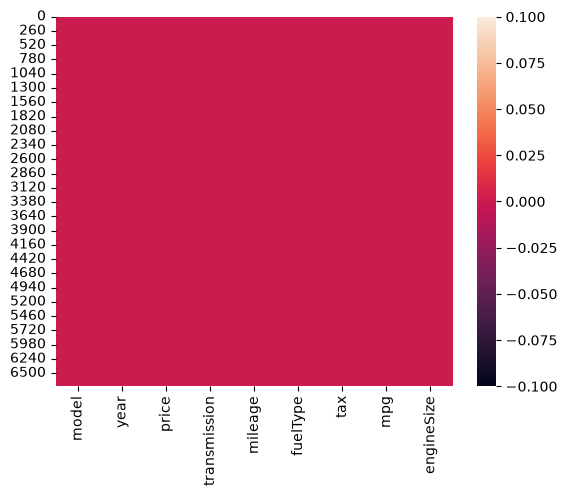

In [12]:
sns.heatmap(df.isnull())

In [13]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000
mean,2016.748145,12522.391066,22857.413921,94.697240,630.422232,14.712971
std,2.204062,6345.017587,19125.464147,73.880776,158.367103,4.361586
min,1998.000000,850.000000,2.000000,0.000000,28.000000,0.000000
25%,2016.000000,8290.000000,9446.000000,0.000000,554.000000,10.000000
50%,2017.000000,10795.000000,18513.000000,135.000000,628.000000,15.000000
75%,2018.000000,14995.000000,31063.750000,145.000000,690.000000,18.000000
max,2020.000000,59995.000000,174419.000000,565.000000,2350.000000,45.000000


# Visualisasi Data

<Axes: >

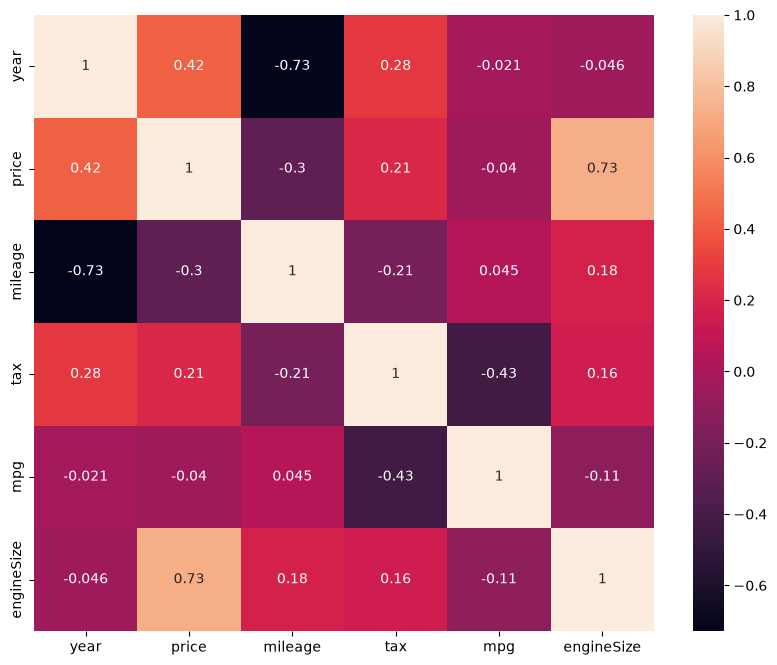

In [16]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Jumlah mobil berdasarkan model

In [29]:
models = (
df.groupby('model')['tax']
.count()
.reset_index(name='numberOfCars')
.sort_values(by='numberOfCars', ascending=False)
)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, ' Yaris'),
  Text(1, 0, ' Aygo'),
  Text(2, 0, ' Auris'),
  Text(3, 0, ' C-HR'),
  Text(4, 0, ' RAV4'),
  Text(5, 0, ' Corolla'),
  Text(6, 0, ' Prius'),
  Text(7, 0, ' Avensis'),
  Text(8, 0, ' Verso'),
  Text(9, 0, ' Hilux'),
  Text(10, 0, ' GT86'),
  Text(11, 0, ' Land Cruiser'),
  Text(12, 0, ' PROACE VERSO'),
  Text(13, 0, ' Supra'),
  Text(14, 0, ' Camry'),
  Text(15, 0, ' IQ'),
  Text(16, 0, ' Urban Cruiser'),
  Text(17, 0, ' Verso-S')])

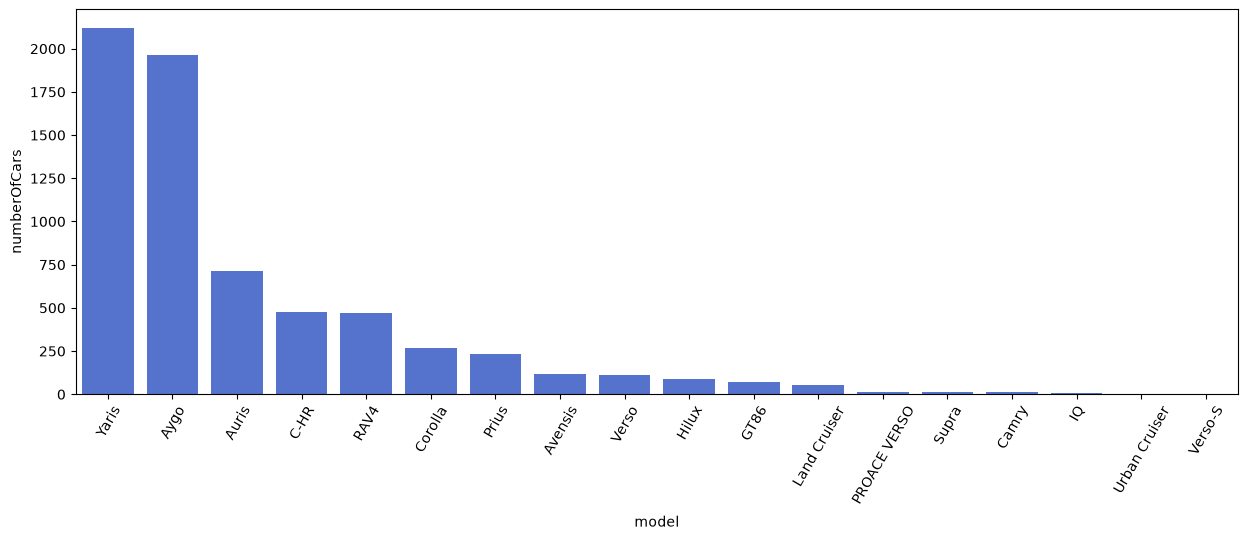

In [30]:
plt.figure(figsize=(15,5))
sns.barplot(x=models['model'], y=models['numberOfCars'],  color='royalblue')
plt.xticks(rotation=60)

# ukuran mesin

In [31]:
engine = df.groupby('engineSize').count()[['tax']].sort_values(by='tax').reset_index()
engine = engine.rename(columns={'tax':'count'})

<Axes: xlabel='engineSize', ylabel='count'>

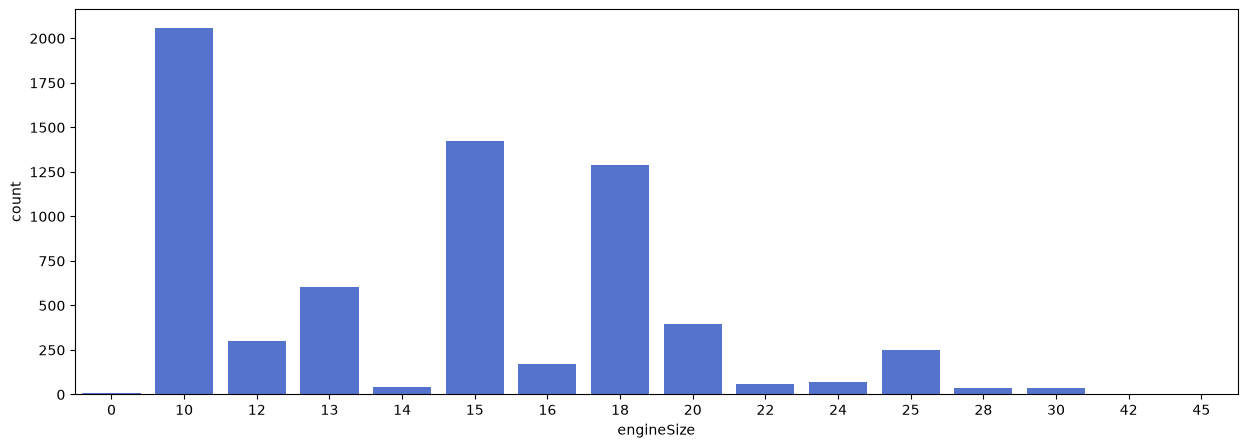

In [32]:
plt.figure(figsize=(15,5))
sns.barplot(x=engine['engineSize'], y=engine['count'], color='royalblue')

# distribusi mileage

<Axes: xlabel='mileage', ylabel='Density'>

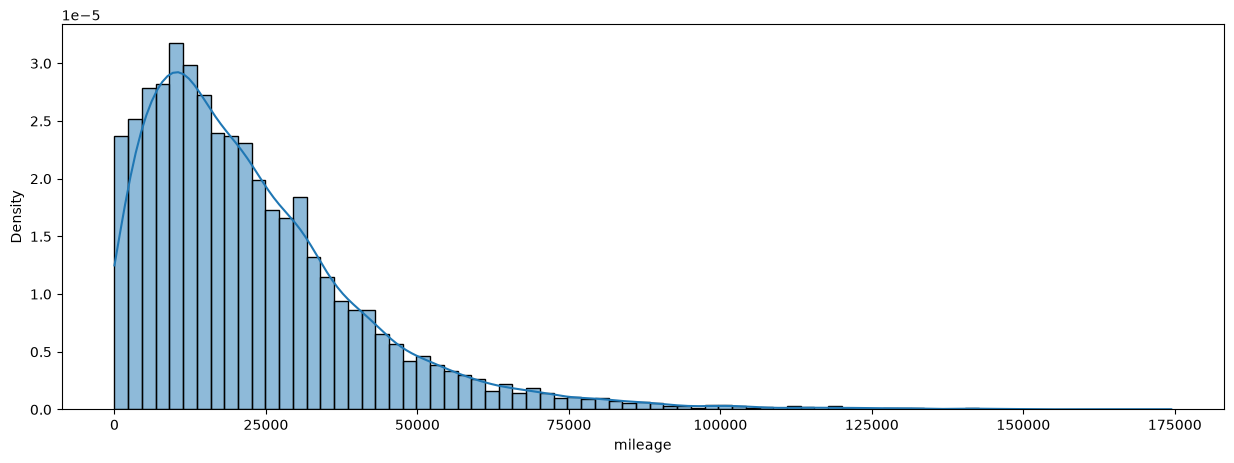

In [39]:
plt.figure(figsize=(15, 5))
sns.histplot(df['mileage'], kde=True, stat='density')

# distribusi harga mobil

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_34412\3048279456.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['price'])


<Axes: xlabel='price', ylabel='Density'>

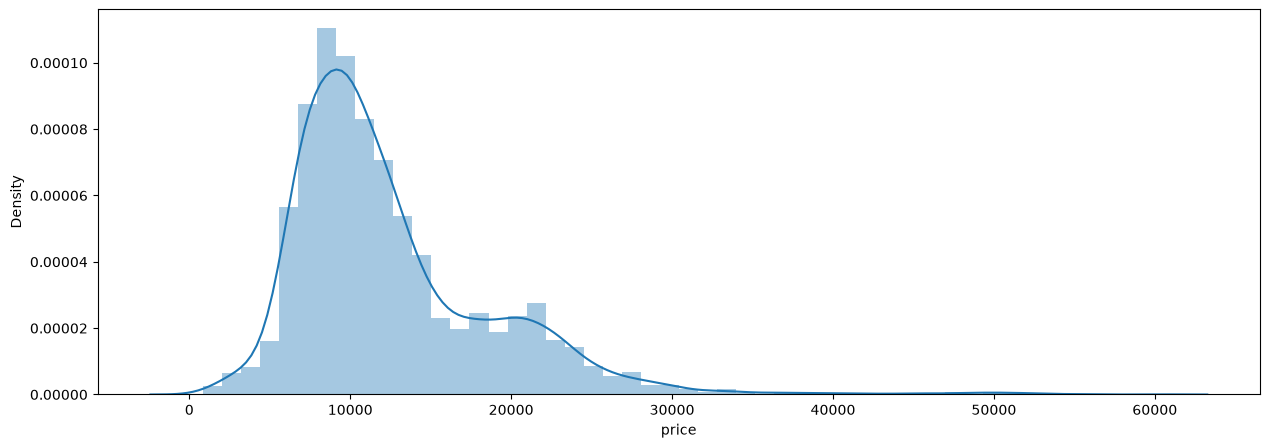

In [40]:
plt.figure(figsize=(15,5))
sns.distplot(df['price'])

# seleksi fitur

In [42]:
features = ['year','mileage','tax','mpg','engineSize']
x = df[features]
y = df['price']
x.shape, y.shape

((6738, 5), (6738,))

# split data training dan data testing

In [50]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 5.2 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/8.4 MB 4.4 MB/s eta 0:00:02
   ------------ --------------------------- 2.6/8.4 MB 4.3 MB/s eta 0:00:02
   --------------- ------------------------ 3.1/8.4 MB 4.2 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.4 MB 4.0 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 4.0 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.4 MB 3.9 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.4 MB 3.8 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 3.8 MB/s eta 0:00:01
   ------------------------------------- -- 7.9/8.4 MB 3.9 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 3.8 MB/s  0:00:02
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -----------------------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [51]:
from sklearn.model_selection import train_test_split
x_train, X_test, y_train, y_test = train_test_split(x,y,random_state=70)
y_test.shape

(1685,)

# membuat model regresi linier

In [52]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)
pred = lr.predict(X_test)


In [53]:
score = lr.score(X_test, y_test)
print('akurasi model regresi linier = ', score)

akurasi model regresi linier =  0.767898331447521


# membuat inputan model regresi linier

In [57]:
print(list(x.columns))

['year', 'mileage', 'tax', 'mpg', 'engineSize']


In [60]:
print("Raw prediction:", lr.predict(input_data))
print("Intercept:", lr.intercept_)
for col, coef in zip(x.columns, lr.coef_):
    print(f"{col}: {coef}")

Raw prediction: [-280.84376142]
Intercept: -1672415.4338704268
year: 827.2815397093968
mileage: -0.08024716764322
tax: -0.9193668058705607
mpg: 2.1837836582361967
engineSize: 1160.8775971611726


c:\Users\LENOVO\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [61]:
import pandas as pd

input_df = pd.DataFrame([[2019, 5000, 145, 30.2, 2]], columns=x.columns)
prediction = lr.predict(input_df)
print('Estimasi harga mobil dalam EUR :', np.maximum(0, prediction))

Estimasi harga mobil dalam EUR : [0.]


In [65]:
#Year=2020, mileage=2000, tax=150, mpg=30.2, engineSize=2
input_data = np.array([[2020,2000,150,30.2,2]])

prediction = lr.predict(input_data)
print('Estimasi harga mobil dalam EUR :', np.maximum(0, prediction))

Estimasi harga mobil dalam EUR : [782.58244719]


c:\Users\LENOVO\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# save model

In [63]:
import pickle

filename = 'estimasi_mobil.sav'
pickle.dump(lr,open(filename,'wb'))